In [15]:
from langgraph.graph import StateGraph,START,END,MessagesState
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_tavily import TavilySearch

In [16]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

In [17]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-120b")

In [18]:
class SupervisorState(MessagesState):
    """state for multiagent system"""
    next_agent:str
    research_data:str
    analysis:str
    final_report:str
    taskcomplete:bool=False
    current_task:str

In [19]:
from langchain_community.tools.tavily_search import TavilySearchResults

@tool
def search_query(query: str) -> str:
    """Search the web for information related to a query."""

    tavily = TavilySearchResults(max_results=3)
    results = tavily.invoke({"query": query})

    return str(results)


@tool
def write_summary(content: str) -> str:
    """Return a shortened version of the provided content."""

    return f"Summary of findings:\n\n{content[:4000]}"

In [20]:
from langchain_core.messages import SystemMessage, HumanMessage
def researcher_agent(state: SupervisorState):

    # Make search_query available to the LLM.
    researcher_llm = llm.bind_tools([search_query])

    system_msg = SystemMessage(
        content="""
        You are a researcher.

        Research the user's task using web search when needed.
        Use the search_query tool to find relevant information.
        After receiving search results, explain your findings clearly.
        Do not invent facts.
        """
    )

    # Invoke the LLM with the instructions and conversation.
    response = researcher_llm.invoke(
        [system_msg] + state["messages"]
    )

    # If a tool was requested, let the graph execute it.
    if response.tool_calls:
        return {"messages": [response]}

    # Otherwise, research is finished.
    return {
        "messages": [response],
        "research_data": response.content,
        "current_task": "Research completed"
    }

In [21]:

def analysis_agent(state: SupervisorState):

    system_msg = SystemMessage(
        content=f"""
        You are an analysis agent.

        Analyze the research findings below.
        Identify important themes, patterns, conclusions,
        and limitations. Do not invent statistics.

        Research findings:
        {state.get("research_data", "")}
        """
    )

    response = llm.invoke(
        [
            system_msg,
            HumanMessage(
                content="Analyze the research findings and explain the results."
            )
        ]
    )

    return {
        "messages": [response],
        "analysis": response.content,
        "current_task": "Analysis completed"
    }


In [22]:

def writer_agent(state: SupervisorState):

    writer_llm = llm.bind_tools([write_summary])

    system_msg = SystemMessage(
        content="""
        You are a professional report writer.

        Write a concise report using the research and analysis provided.
        Include:
        1. Introduction
        2. Key findings
        3. Analysis
        4. Conclusion
        5. Recommendations

        Keep the report under 500 words.
        Do not repeat the entire research data.
        Do not invent facts.
        """
    )

    # Send only the required findings, not all messages.
    user_msg = HumanMessage(
        content=(
            f"Research findings:\n{state.get('research_data', '')[:4000]}\n\n"
            f"Analysis:\n{state.get('analysis', '')[:3000]}\n\n"
            "Write a concise final report."
        )
    )

    response = writer_llm.invoke([system_msg, user_msg])

    if response.tool_calls:
        return {"messages": [response]}

    return {
        "messages": [response],
        "final_report": response.content,
        "taskcomplete": True,
        "current_task": "Report completed"
    }


In [23]:

def supervisor_agent(state: SupervisorState):

    # Stop if the report has been completed.
    if state.get("taskcomplete", False):
        return {"next_agent": "END"}

    # Select the first unfinished stage.
    if not state.get("research_data"):
        return {"next_agent": "researcher"}

    if not state.get("analysis"):
        return {"next_agent": "analysis"}

    if not state.get("final_report"):
        return {"next_agent": "writer"}

    return {"next_agent": "END"}

In [24]:
researcher_tools = ToolNode([search_query])
writer_tools = ToolNode([write_summary])

graph = StateGraph(SupervisorState)

graph.add_node("supervisor", supervisor_agent)
graph.add_node("researcher", researcher_agent)
graph.add_node("analysis", analysis_agent)
graph.add_node("writer", writer_agent)

graph.add_node("researcher_tools", researcher_tools)
graph.add_node("writer_tools", writer_tools)


# Start with the supervisor.
graph.add_edge(START, "supervisor")


# Supervisor selects the next worker.
graph.add_conditional_edges(
    "supervisor",
    lambda state: state["next_agent"],
    {
        "researcher": "researcher",
        "analysis": "analysis",
        "writer": "writer",
        "END": END
    }
)


# Researcher: call tools when requested.
graph.add_conditional_edges(
    "researcher",
    tools_condition,
    {
        "tools": "researcher_tools",
        END: "supervisor"
    }
)

# After searching, return to the researcher.
graph.add_edge("researcher_tools", "researcher")


# Analysis finishes and returns to the supervisor.
graph.add_edge("analysis", "supervisor")


# Writer: call its tool when requested.
graph.add_conditional_edges(
    "writer",
    tools_condition,
    {
        "tools": "writer_tools",
        END: "supervisor"
    }
)

# After using the summary tool, return to the writer.
graph.add_edge("writer_tools", "writer")


# Compile the graph.
app = graph.compile()


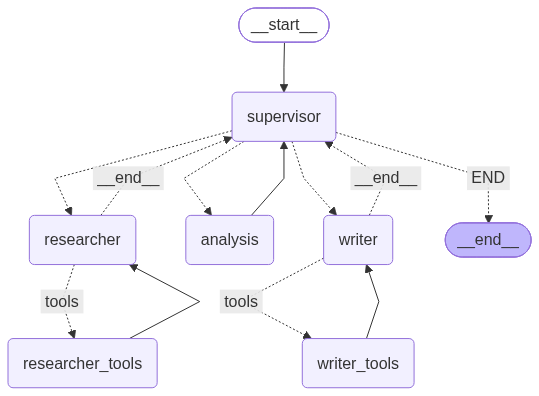

In [25]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [26]:
result = app.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "Research how AI is transforming healthcare, "
                    "analyze the findings, and write a final report."
                )
            )
        ]
    }
)

In [27]:
print(result["final_report"])

**Report – How Artificial Intelligence Is Transforming Healthcare (2023‑2024)**  
*Prepared for: [Your Organization]*  
*Date: 9 Oct 2026*  

---

### 1. Introduction  

The convergence of massive health‑data growth, mature deep‑learning methods, and supportive regulatory pathways has moved AI from experimental labs into everyday clinical practice. This report synthesises publicly available evidence from 2023‑2024 (FDA clearance logs, peer‑reviewed studies, industry analyses) to outline where AI is delivering value, where gaps remain, and what actions your organization should consider.

---

### 2. Key Findings  

| Domain | AI‑Enabled Advance (2023‑24) | Evidential Highlight | Primary Benefit |
|--------|-----------------------------|----------------------|-----------------|
| **Diagnostics – Imaging** | > 700 FDA‑cleared AI algorithms for radiology (723 of 950 total clearances) | FDA database (July 2024) | Faster, more reproducible reads; workload reduction |
| **Diagnostics – Mammog